# Exploratory Data Analysis
This notebook aims to explore the dataset to gain additional insights.

In [43]:
!pip install -qqq emoji fasttext

ERROR: Could not build wheels for fasttext, which is required to install pyproject.toml-based projects


In [44]:
# Import packages
import os
import pandas as pd
import numpy as np
import itertools
import collections
import networkx as nx
import six
import matplotlib.pyplot as plt
import seaborn as sns
# import emoji as em
# import fasttext

from keras.preprocessing.text import Tokenizer
from wordcloud import WordCloud
from textblob import TextBlob
from sklearn.model_selection import train_test_split

import nltk
from nltk import tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.sentiment.util import *
from nltk.corpus import stopwords
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [46]:
# Set constants
SEED = 4222

## Original Dataset

In [47]:
# Load dataset
df = pd.read_csv('./dataset/Suicide_Detection.csv', index_col=0)
df.reset_index(drop=True, inplace=True)
df.head()

,text,class
0,Ex Wife Threatening SuicideRecently I left my ...,suicide
1,Am I weird I don't get affected by compliments...,non-suicide
2,Finally 2020 is almost over... So I can never ...,non-suicide
3,i need helpjust help me im crying so hard,suicide
4,"I’m so lostHello, my name is Adam (16) and I’v...",suicide


In [48]:
# Check for null values
df.isnull().sum()

text     0
class    0
dtype: int64

class
suicide        116037
non-suicide    116037
Name: count, dtype: int64
class
suicide        0.5
non-suicide    0.5
Name: proportion, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\68271138.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['class'], palette=['red', 'green'])


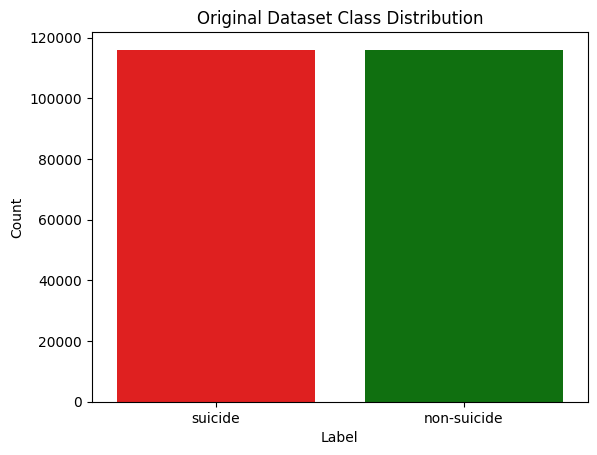

In [90]:
# Check class distribution
print(df['class'].value_counts())
print(df['class'].value_counts(normalize=True))

sns.countplot(x=df['class'], palette=['red', 'green'])
plt.title('Original Dataset Class Distribution')
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

In [50]:
# Check lowercase
lowercase = df['text'].str.islower()
print(lowercase.value_counts())

# df['text'][lowercase == True]

text
False    214395
True      17679
Name: count, dtype: int64


In [51]:
# Check extra whitespace
extra_whitespace = df['text'].str.match('\s\s+')
print(extra_whitespace.value_counts())

# df['text'][extra_whitespace == True]

text
False    232073
True          1
Name: count, dtype: int64


In [52]:
# Check URL
url = df['text'].str.contains("http")
print(url.value_counts())

# df['text'][url == True]

text
False    224921
True       7153
Name: count, dtype: int64


In [53]:
# Check mentions
mention = df['text'].str.match('@(\w+)')
print(mention.value_counts())

# df['text'][mention == True]

text
False    232072
True          2
Name: count, dtype: int64


In [54]:
# Check hashtags
hashtag = df['text'].str.match('#(\w+)')
print(hashtag.value_counts())

# df['text'][hashtag == True]

text
False    232061
True         13
Name: count, dtype: int64


In [55]:
# Check subreddit tag
subreddit = df['text'].str.match('r/(\w+)')
print(subreddit.value_counts())

# df['text'][subreddit == True]

text
False    231990
True         84
Name: count, dtype: int64


In [56]:
# Check users tag
users = df['text'].str.match('u/(\w+)')
print(users.value_counts())

# df['text'][users == True]

text
False    231859
True        215
Name: count, dtype: int64


In [57]:
# Check special characters
special_characters = df['text'].str.match('[^0-9a-zA-Z]+')
print(special_characters.value_counts())

# df['text'][special_characters == True]

text
False    229638
True       2436
Name: count, dtype: int64


## Cleaned Dataset

In [58]:
# Load dataset
clean_df = pd.read_csv('./dataset/processed.csv', header=0)
clean_df

,text,class
0,ex wife threatening suiciderecently left wife ...,suicide
1,weird dont get affected compliment coming some...,non-suicide
2,finally 2020 almost never hear 2020 bad year e...,non-suicide
3,need helpjust help im cry hard,suicide
4,im losthello name adam 16 ive struggling year ...,suicide
...,...,...
232069,dont like rock going get anything go httpsmusi...,non-suicide
232070,tell many friend lonely everything deprived pr...,non-suicide
232071,pee probably taste like salty tea someone dran...,non-suicide
232072,usual stuff find hereim posting sympathy pity ...,suicide


In [59]:
# Check for null values
clean_df.isnull().sum()

text     32
class     0
dtype: int64

In [60]:
# Split dataset into train and test sets 
train_data, test_data = train_test_split(clean_df,
                                         test_size=0.2, 
                                         random_state=SEED,
                                         stratify=clean_df['class'])

In [61]:
# Split train set into classes
train_data_suicidal = train_data[train_data['class'] == "suicide"]
train_data_nonsuicidal = train_data[train_data['class'] == "non-suicide"]

In [62]:
train_data_suicidal

,text,class
97322,im sure title thisi struggled thought suicide ...,suicide
142663,want attempted suicide wont test testsi feelin...,suicide
97904,dont know say anymoreits said reason want die ...,suicide
223583,kinda like habit killing mei think ive passive...,suicide
81107,suicide becoming option lefteveryday get harde...,suicide
...,...,...
82269,started clock hear tickingi said id give time ...,suicide
77493,hi attention seeker hereeven tough im attentio...,suicide
25486,boyfriend confessed something destroyedboyfrie...,suicide
115668,hate aliveyou know maybe one fucking time some...,suicide


### Full dataset

class
suicide        116037
non-suicide    116037
Name: count, dtype: int64
class
suicide        0.5
non-suicide    0.5
Name: proportion, dtype: float64


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\3134083345.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=clean_df['class'], palette=['red', 'green'])


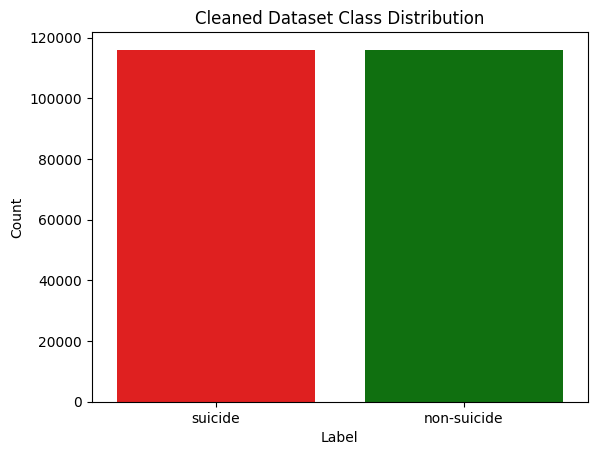

In [91]:
# Check class distribution
print(clean_df['class'].value_counts())
print(clean_df['class'].value_counts(normalize=True))

sns.countplot(x=clean_df['class'], palette=['red', 'green'])
plt.title('Cleaned Dataset Class Distribution')
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

### Train dataset

class
suicide        92830
non-suicide    92829
Name: count, dtype: int64
class
suicide        0.500003
non-suicide    0.499997
Name: proportion, dtype: float64


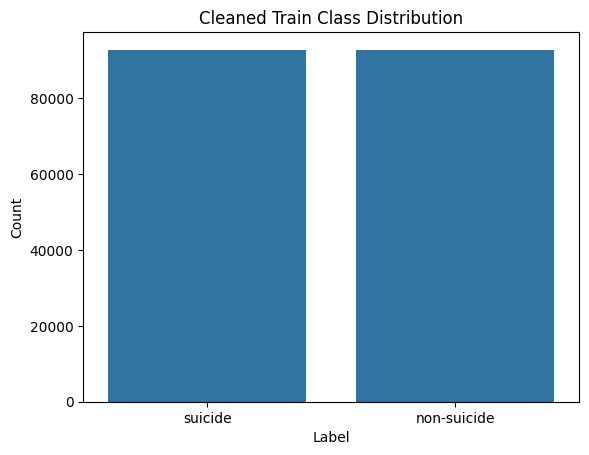

In [64]:
# Check class distribution
print(train_data['class'].value_counts())
print(train_data['class'].value_counts(normalize=True))

sns.countplot(x=train_data['class'])
plt.title('Cleaned Train Class Distribution')
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

## Suicidal Text

In [65]:
train_data_suicidal['text'] = train_data_suicidal['text'].astype(str)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\742097099.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_suicidal['text'] = train_data_suicidal['text'].astype(str)


In [66]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts(train_data_suicidal['text'])

In [67]:
tokenizer.word_counts.items()

odict_items([('im', 223014), ('sure', 13050), ('title', 1043), ('thisi', 384), ('struggled', 1266), ('thought', 34739), ('suicide', 27806), ('long', 17730), ('remember', 6878), ('really', 52188), ('tired', 16547), ('ive', 78163), ('stage', 575), ('constant', 3366), ('cry', 10859), ('anger', 1910), ('loathing', 192), ('feel', 95979), ('like', 106015), ('every', 25980), ('emotion', 3171), ('could', 29808), ('felt', 14103), ('heart', 4900), ('point', 21166), ('nothing', 28426), ('hope', 12938), ('hoping', 2221), ('somehow', 2713), ('suppose', 1085), ('everyone', 20645), ('however', 3575), ('recently', 5980), ('past', 12044), ('month', 20874), ('there', 12165), ('new', 9284), ('feeling', 23824), ('two', 11502), ('maybe', 14814), ('actually', 12613), ('content', 685), ('acceptance', 215), ('accepting', 397), ('fate', 455), ('supposed', 4254), ('card', 996), ('whole', 7196), ('time', 68050), ('playing', 1993), ('game', 4434), ('wasnt', 9527), ('win', 728), ('way', 33298), ('end', 29321), ('w

In [68]:
word_freq_suicidal = pd.DataFrame(tokenizer.word_counts.items(), columns=['word','count']).sort_values(by='count', ascending=False)

### Word Frequency Bar Graph

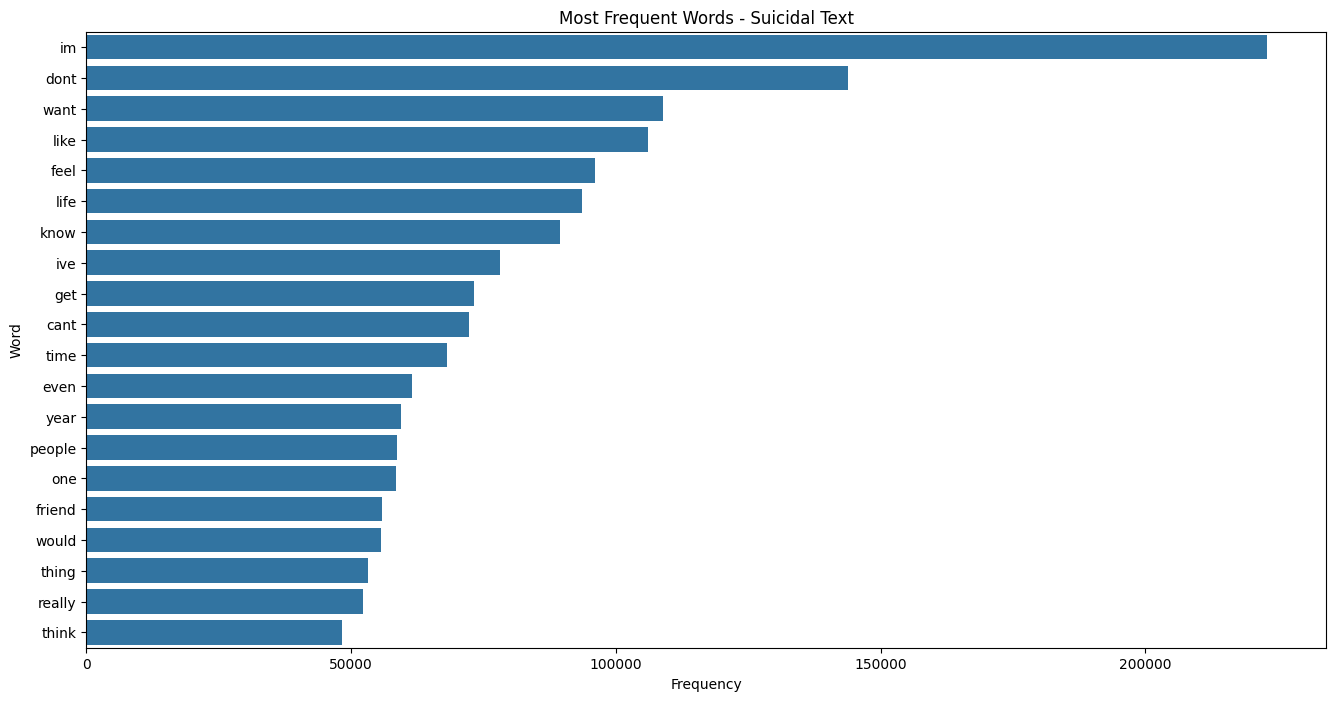

In [69]:
# Word Frequency Bar Graph
plt.figure(figsize=(16, 8))
sns.barplot(x='count',y='word',data=word_freq_suicidal.iloc[:20])
plt.title('Most Frequent Words - Suicidal Text')
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

### Wordcloud

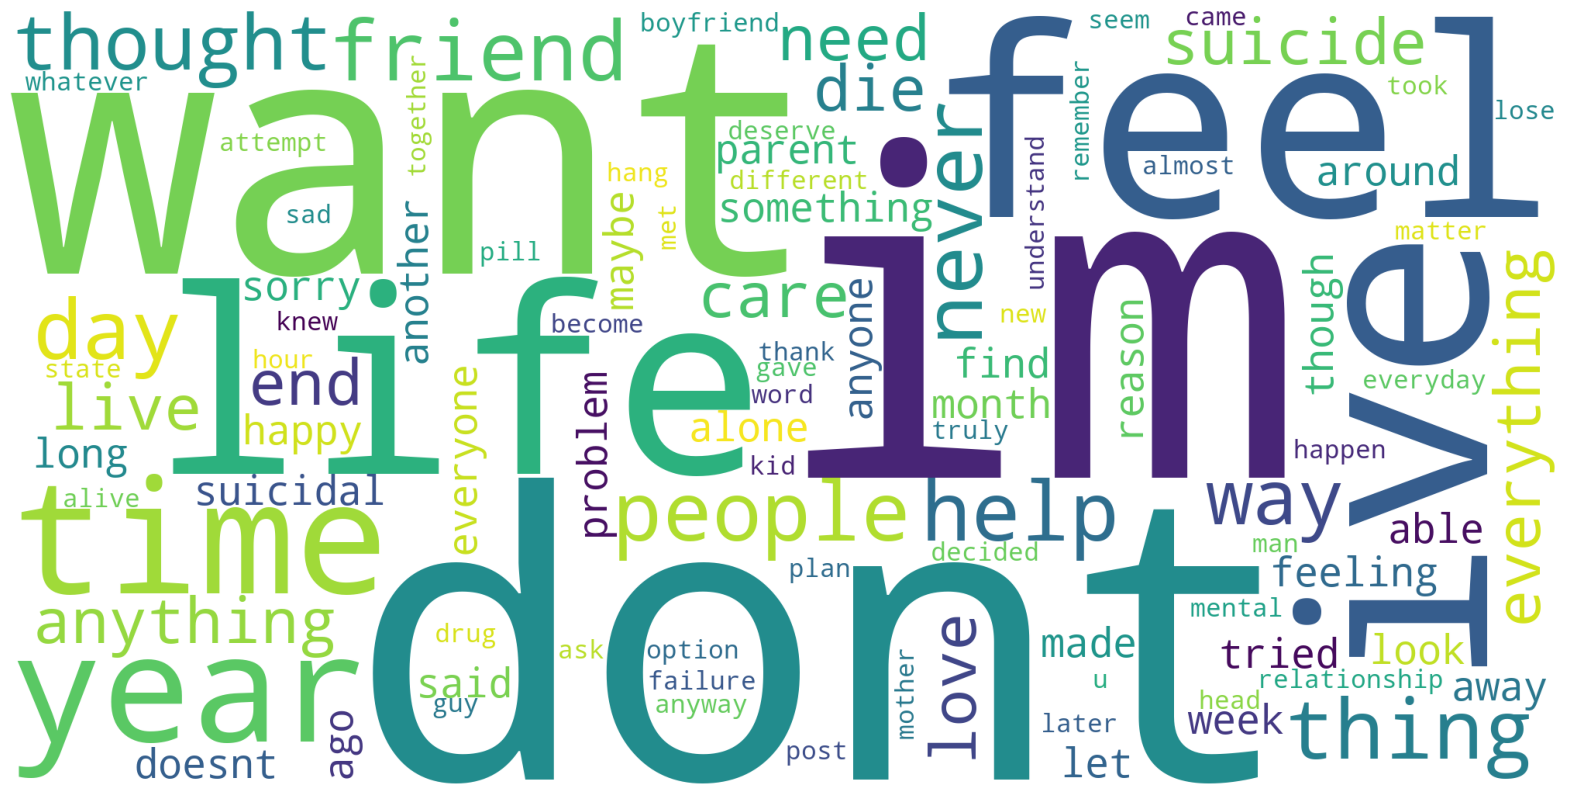

In [70]:
# Wordcloud 
feature_names=word_freq_suicidal['word'].values
wc=WordCloud(max_words=100, background_color="white", width=2000, height=1000)
wc.generate(' '.join(word for word in feature_names))
plt.figure(figsize=(20,15))
plt.axis('off')
plt.imshow(wc)
plt.show()

### Distribution of Text Length

In [71]:
# Get average text length
train_data_suicidal['text'] = train_data_suicidal['text'].astype('str')
train_data_suicidal['length'] = train_data_suicidal['text'].apply(lambda x: len(x.split()))

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\4217230235.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_suicidal['text'] = train_data_suicidal['text'].astype('str')
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\4217230235.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_suicidal['length'] = train_data_suicidal['text'].apply(lambda x: len(x.split()))


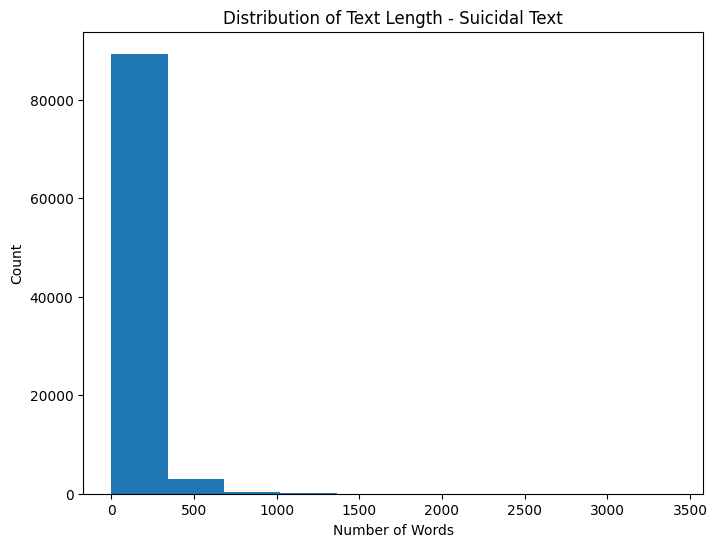

In [72]:
# Plot average text length
ax = train_data_suicidal['length'].plot(kind='hist',title='Distribution of Text Length - Suicidal Text', figsize=(8,6))
ax.set_xlabel("Number of Words")
ax.set_ylabel("Count")
plt.show()

### Polarity Score Distribution

In [73]:
# Polarity score distribution
def get_polarity(text):
  return TextBlob(text).sentiment.polarity
train_data_suicidal['Polarity'] = train_data_suicidal['text'].apply(get_polarity)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\692241912.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_suicidal['Polarity'] = train_data_suicidal['text'].apply(get_polarity)


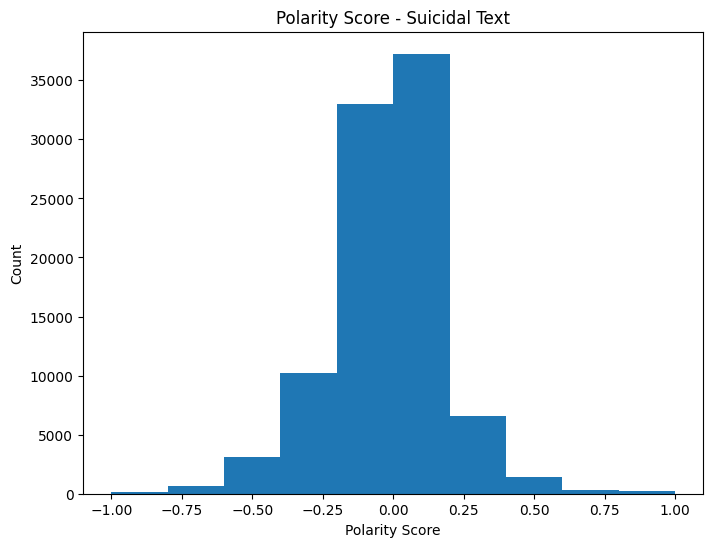

In [74]:
# Plot polarity score graph
ax = train_data_suicidal['Polarity'].plot(kind='hist', title='Polarity Score - Suicidal Text', figsize=(8,6))
ax.set_xlabel("Polarity Score")
ax.set_ylabel("Count")
plt.show()

### Bigram

In [75]:
#Remove more stop words and do bigram
import nltk
nltk.download('stopwords')
stop_words = stopwords.words('english')
train_data_suicidal['without_stopwords'] = train_data_suicidal['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))

from nltk import bigrams
sentences = [text.split() for text in train_data_suicidal['without_stopwords']]

# Create list of lists containing bigrams in tweets
terms_bigram = [list(bigrams(text)) for text in sentences]

# Flatten list of bigrams in clean tweets
bigrams = list(itertools.chain(*terms_bigram))

# Create counter of words in clean bigrams
bigram_counts = collections.Counter(bigrams)

#Create a table of the top 20 most paired words
bigram_df = pd.DataFrame(bigram_counts.most_common(20),
                             columns=['Bigram', 'Count'])

bigram_df

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\2993072545.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_suicidal['without_stopwords'] = train_data_suicidal['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))


,Bigram,Count
0,"(feel, like)",36975
1,"(dont, know)",33189
2,"(dont, want)",28553
3,"(im, going)",11496
4,"(want, die)",10196
5,"(im, tired)",8769
6,"(like, im)",8764
7,"(dont, think)",7784
8,"(know, im)",7456
9,"(gon, na)",7241


<Axes: >

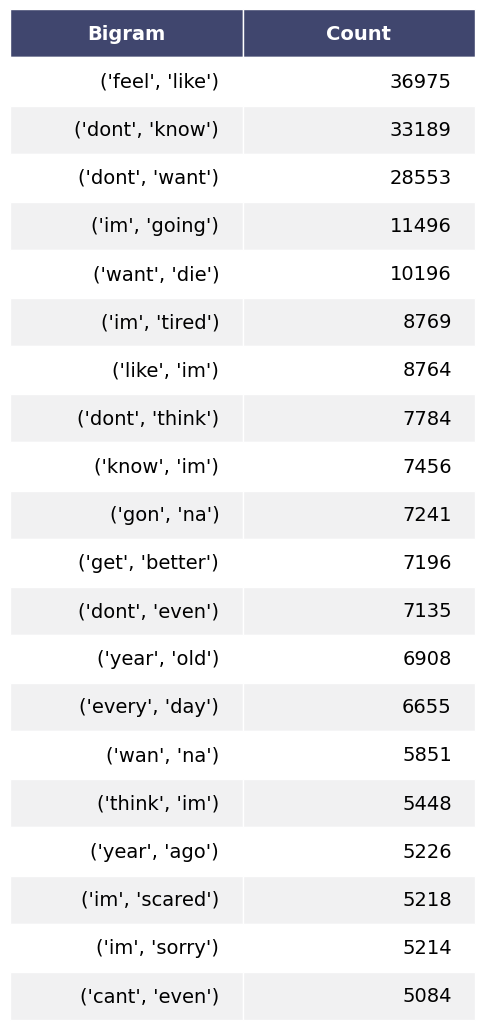

In [76]:
#To make the table nicer
def render_mpl_table(data, col_width=3.0, row_height=0.625, font_size=14,
                     header_color='#40466e', row_colors=['#f1f1f2', 'w'], edge_color='w',
                     bbox=[0, 0, 1, 1], header_columns=0,
                     ax=None, **kwargs):
    if ax is None:
        size = (np.array(data.shape[::-1]) + np.array([0, 1])) * np.array([col_width, row_height])
        fig, ax = plt.subplots(figsize=size)
        ax.axis('off')

    mpl_table = ax.table(cellText=data.values, bbox=bbox, colLabels=data.columns, **kwargs)

    mpl_table.auto_set_font_size(False)
    mpl_table.set_fontsize(font_size)

    for k, cell in  six.iteritems(mpl_table._cells):
        cell.set_edgecolor(edge_color)
        if k[0] == 0 or k[1] < header_columns:
            cell.set_text_props(weight='bold', color='w')
            cell.set_facecolor(header_color)
        else:
            cell.set_facecolor(row_colors[k[0]%len(row_colors) ])
    return ax

render_mpl_table(bigram_df, header_columns=0, col_width=3)

## Non-suicidal Text

In [77]:
train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype(str)


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\60644925.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype(str)


In [78]:
tokenizer_nonsuicidal = Tokenizer()
tokenizer_nonsuicidal.fit_on_texts(train_data_nonsuicidal["text"])

In [79]:
tokenizer_nonsuicidal.word_counts.items()

odict_items([('boy', 3090), ('failed', 417), ('didnt', 6774), ('need', 9585), ('wisdom', 82), ('tldr', 605), ('bottom', 424), ('okay', 1747), ('backstory', 97), ('year', 11254), ('round', 299), ('competitive', 58), ('swimming', 93), ('got', 12495), ('invited', 238), ('ncsa', 1), ('meet', 1069), ('orlando', 8), ('big', 2733), ('deal', 934), ('national', 158), ('since', 4272), ('pretty', 4111), ('hard', 2981), ('get', 21740), ('one', 17126), ('girl', 11316), ('went', 3634), ('14under', 1), ('strict', 158), ('rule', 771), ('im', 50269), ('going', 8286), ('date', 1512), ('drive', 634), ('3', 4054), ('people', 17846), ('seriously', 1185), ('made', 5642), ('reconsider', 11), ('decision', 356), ('happened', 2603), ('anyhow', 10), ('throughout', 230), ('4', 2338), ('day', 18841), ('long', 3632), ('event', 362), ('hanging', 395), ('bleacher', 10), ('talking', 4032), ('laughing', 445), ('stuff', 4309), ('mind', 2099), ('lightly', 30), ('offensive', 161), ('humor', 207), ('patronizing', 5), ('who

In [80]:
word_freq_nonsuicidal = pd.DataFrame(tokenizer_nonsuicidal.word_counts.items(), columns=['word','count']).sort_values(by='count', ascending=False)
word_freq_nonsuicidal.head()

,word,count
31,im,50269
503,filler,46487
70,like,41277
117,dont,27585
24,get,21740


### Word Frequency Bar Graph

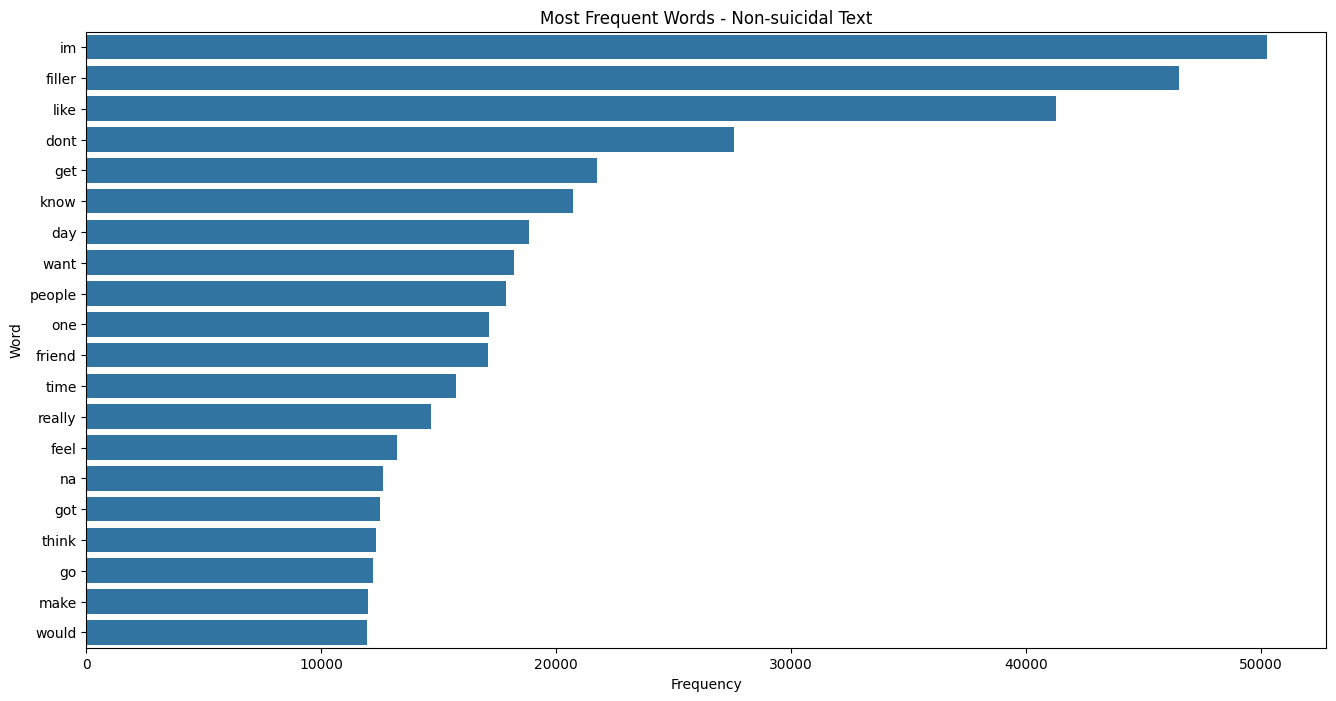

In [81]:
# Word Frequency Bar Graph
plt.figure(figsize=(16, 8))
sns.barplot(x='count', y='word', data=word_freq_nonsuicidal.iloc[:20])
plt.title('Most Frequent Words - Non-suicidal Text')
plt.xlabel("Frequency")
plt.ylabel("Word")
plt.show()

### Wordcloud

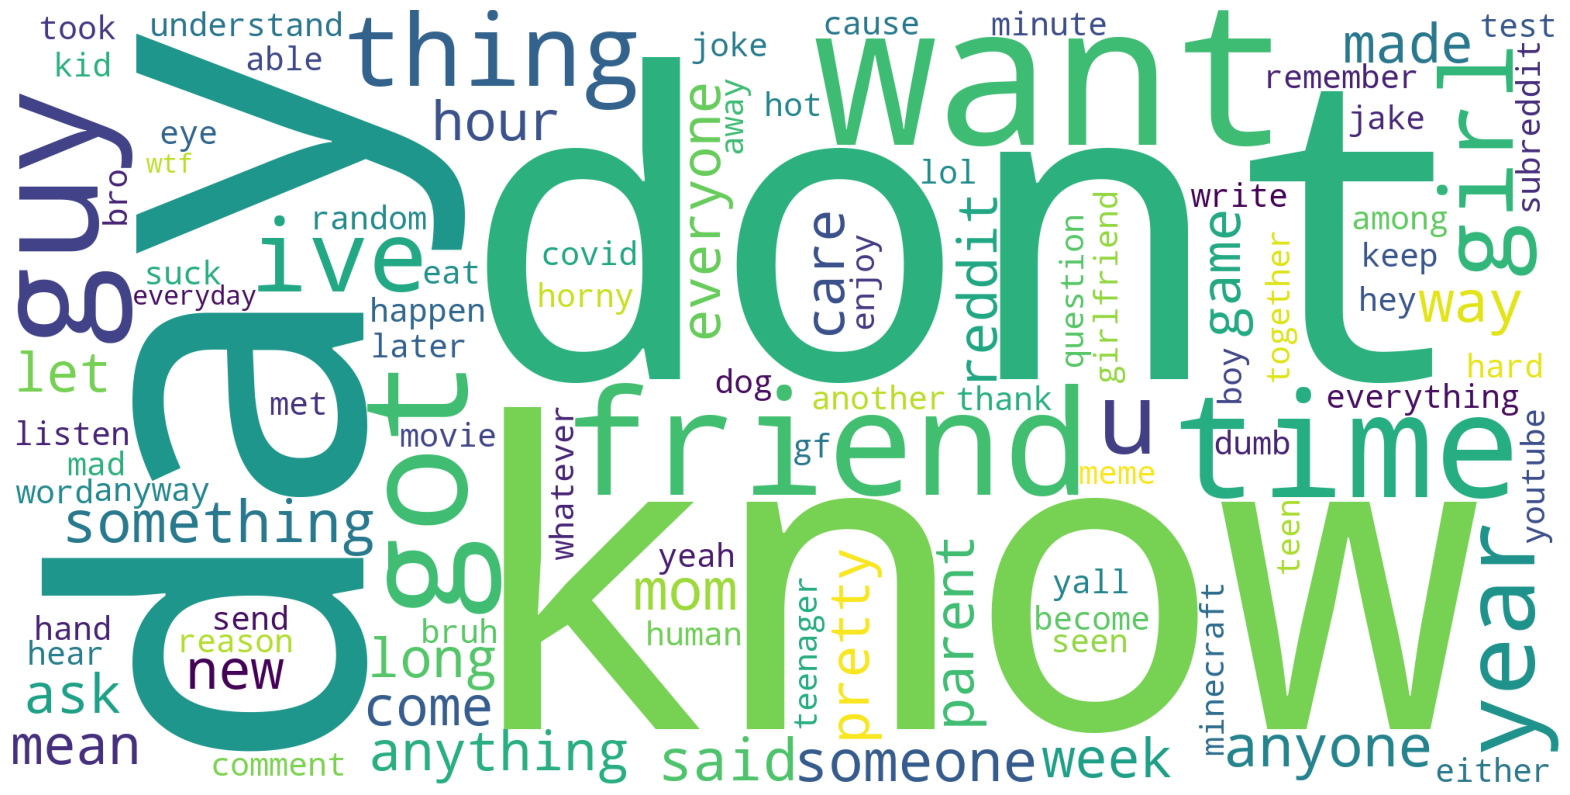

In [82]:
# Wordcloud  
feature_names_nonsuicidal = word_freq_nonsuicidal['word'].values
wc = WordCloud(max_words=100, background_color="white", width=2000, height=1000)
wc.generate(' '.join(word for word in feature_names_nonsuicidal))
plt.figure(figsize=(20,15))
plt.axis('off')
plt.imshow(wc)
plt.show()

### Distribution of Text Length

In [83]:
# Get average text length
train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype('str')
train_data_nonsuicidal['length'] = train_data_nonsuicidal['text'].apply(lambda x: len(x.split()))

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\4112220707.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype('str')
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\4112220707.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['length'] = train_data_nonsuicidal['text'].apply(lambda x: len(x.split()))


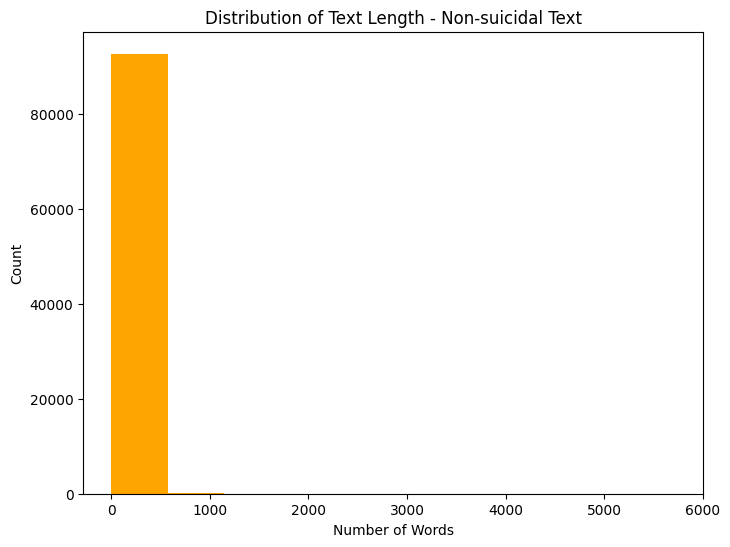

In [84]:
# Plot distribution of text length
ax = train_data_nonsuicidal['length'].plot(kind='hist',title='Distribution of Text Length - Non-suicidal Text', color='orange', figsize=(8,6))
ax.set_xlabel("Number of Words")
ax.set_ylabel("Count")
plt.show()

### Polarity Score Distribution

In [85]:
# Polarity score distribution
train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype('str')
train_data_nonsuicidal['Polarity'] = train_data_nonsuicidal['text'].apply(get_polarity)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\3677677760.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['text'] = train_data_nonsuicidal['text'].astype('str')
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\3677677760.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['Polarity'] = train_data_nonsuicidal['text'].apply(get_polarity)


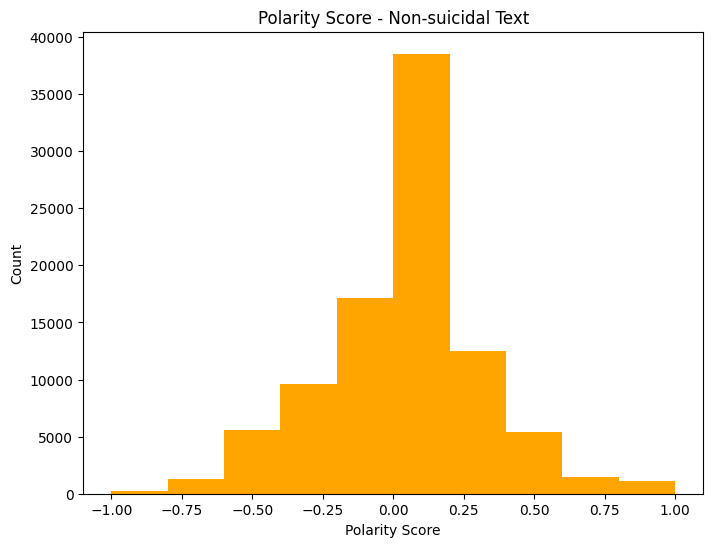

In [86]:
# Plot polarity score graph
ax = train_data_nonsuicidal['Polarity'].plot(kind='hist', title='Polarity Score - Non-suicidal Text', color="orange", figsize=(8,6))
ax.set_xlabel("Polarity Score")
ax.set_ylabel("Count")
plt.show()

### Bigram

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_12488\1853847803.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_data_nonsuicidal['without_stopwords'] = train_data_nonsuicidal['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))


<Axes: >

C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\IPython\core\events.py:93: UserWarning: Glyph 12644 (\N{HANGUL FILLER}) missing from current font.
  func(*args, **kwargs)
C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\IPython\core\events.py:93: UserWarning: Glyph 74795 (\N{CUNEIFORM NUMERIC SIGN NINE SHAR2}) missing from current font.
  func(*args, **kwargs)
C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 12644 (\N{HANGUL FILLER}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\LENOVO\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\LocalCache\local-packages\Python39\site-packages\IPython\core\pylabtools.py:152: User

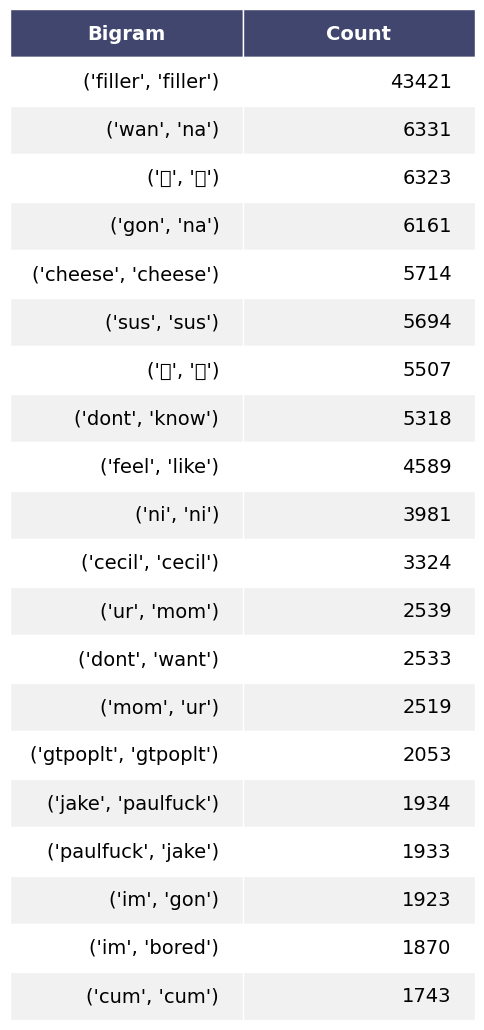

In [87]:
#Remove more stop words and do bigram
stop_words = stopwords.words('english')
train_data_nonsuicidal['without_stopwords'] = train_data_nonsuicidal['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))

from nltk import bigrams
sentences = [text.split() for text in train_data_nonsuicidal['without_stopwords']]

# Create list of lists containing bigrams in tweets
terms_bigram = [list(bigrams(text)) for text in sentences]

# Flatten list of bigrams in clean tweets
bigrams = list(itertools.chain(*terms_bigram))

# Create counter of words in clean bigrams
bigram_counts = collections.Counter(bigrams)

#Create a table of the top 20 most paired words
bigram_df = pd.DataFrame(bigram_counts.most_common(20),
                             columns=['Bigram', 'Count'])

render_mpl_table(bigram_df, header_columns=0, col_width=3)